1. XOR 문제 시각화 창을 확인하세요.


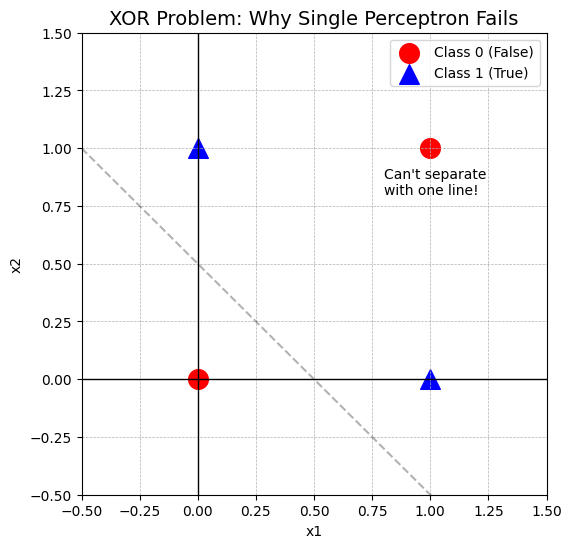

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1단계: XOR 데이터 정의 및 문제 상황 시각화
# ---------------------------------------------------------
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

def plot_xor_problem(X, y):
    plt.figure(figsize=(6, 6))
    plt.title("XOR Problem: Why Single Perceptron Fails", fontsize=14)

    # 0인 데이터 (Circle), 1인 데이터 (Triangle) 산점도
    plt.scatter(X[y==0][:, 0], X[y==0][:, 1], s=200, c='red', marker='o', label='Class 0 (False)')
    plt.scatter(X[y==1][:, 0], X[y==1][:, 1], s=200, c='blue', marker='^', label='Class 1 (True)')

    # 격자 및 축 설정
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.axhline(y=0, color='k', linewidth=1)
    plt.axvline(x=0, color='k', linewidth=1)
    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()

    # 설명: 직선 하나로 빨간점과 파란점을 나눌 수 없음을 시각적으로 보여줌
    # 가상의 직선(실패 예시)을 점선으로 그리기
    x_line = np.linspace(-0.5, 1.5, 10)
    plt.plot(x_line, -x_line + 0.5, 'k--', alpha=0.3, label='Linear Boundary (Fail)')
    plt.text(0.8, 0.8, "Can't separate\nwith one line!", color='black', fontsize=10)

    plt.show()

print("1. XOR 문제 시각화 창을 확인하세요.")
plot_xor_problem(X, y)

In [2]:
def sigmoid(x):
  return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
  return x * (1 - x)

In [16]:
def ReLu(x):
  return np.maximum(0, x)

def ReLu_derivative(x):
  return np.where(x > 0, 1, 0)

In [3]:
np.random.seed(42)
W1 = np.random.uniform(size=(2,4))
b1 = np.random.uniform(size=(1,4))
W2 = np.random.uniform(size=(4,1))
b2 = np.random.uniform(size=(1,1))

l_r = 0.1
epochs = 10000

y_reshaped = y.reshape(-1,1)

In [4]:
loss_history = []

for epoch in range(epochs):
  hidden_input = np.dot(X, W1) + b1
  hidden_output = sigmoid(hidden_input)
  final_input = np.dot(hidden_output, W2) + b2
  pred = sigmoid(final_input)

  error = y_reshaped - pred
  d_pred = error * sigmoid_derivative(pred)
  error_hidden = d_pred.dot(W2.T)
  d_hidden = error_hidden * sigmoid_derivative(hidden_output)

  W2 += hidden_output.T.dot(d_pred) * l_r
  b2 += np.sum(d_pred, axis =0, keepdims=True) * l_r
  W1 += X.T.dot(d_hidden) * l_r
  b1 += np.sum(d_hidden, axis=0, keepdims=True) * l_r

  if epoch % 1000 == 0:
    loss = np.mean(np.square(error))
    loss_history.append(loss)

print("\n2. 학습 완료. 최종 Loss:", loss_history[-1])


2. 학습 완료. 최종 Loss: 0.004863842080358418


3. 학습된 결정 경계 시각화 창을 확인하세요.


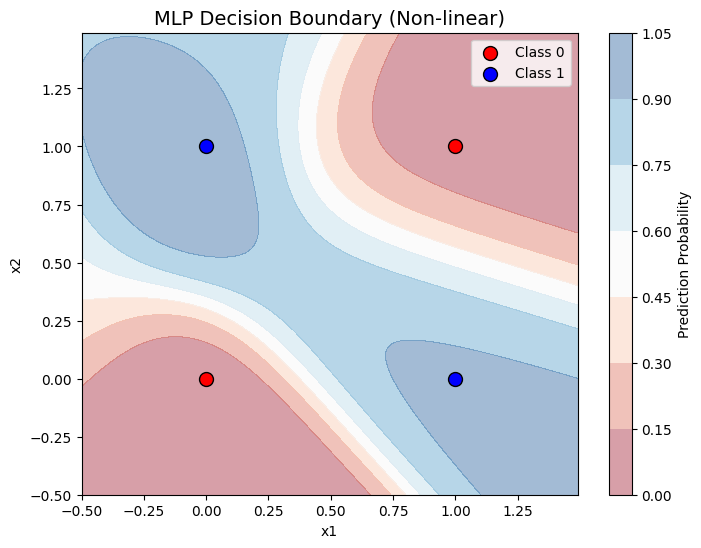

In [10]:
def plot_decision_boundary(X, y, W1, b1, W2, b2):
    plt.figure(figsize=(8, 6))

    # 1. 배경에 등고선(Contour) 그리기 - 모델의 예측값 분포
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    # Meshgrid의 모든 점에 대해 예측 수행
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    h_out = sigmoid(np.dot(grid_points, W1) + b1)
    Z = sigmoid(np.dot(h_out, W2) + b2)
    Z = Z.reshape(xx.shape)

    # 등고선 플롯 (영역 채우기)
    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.RdBu)
    plt.colorbar(label='Prediction Probability')

    # 2. 원래 데이터 포인트 찍기
    plt.scatter(X[y==0][:, 0], X[y==0][:, 1], s=100, c='red', edgecolors='k', label='Class 0')
    plt.scatter(X[y==1][:, 0], X[y==1][:, 1], s=100, c='blue', edgecolors='k', label='Class 1')

    plt.title("MLP Decision Boundary (Non-linear)", fontsize=14)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.show()

print("3. 학습된 결정 경계 시각화 창을 확인하세요.")
plot_decision_boundary(X, y, W1, b1, W2, b2)

In [25]:
np.random.seed(1)
W1_2 = np.random.uniform(-1, 1, size=(2,4))
b1_2 = np.random.uniform(-1, 1, size=(1,4))
W2_2 = np.random.uniform(-1, 1, size=(4,1))
b2_2 = np.random.uniform(-1, 1, size=(1,1))

l_r = 0.1
epochs = 10000

y_reshaped = y.reshape(-1,1)

In [26]:
loss_history = []

for epoch in range(epochs):
  hidden_input = np.dot(X, W1_2) + b1_2
  hidden_output = ReLu(hidden_input) # 은닉층에는 ReLU 사용
  final_input = np.dot(hidden_output, W2_2) + b2_2
  pred = sigmoid(final_input) # 출력층에는 시그모이드 사용 (이진 분류에 적합)

  error = y_reshaped - pred
  d_pred = error * sigmoid_derivative(pred) # 출력층에 맞는 시그모이드 도함수 사용
  error_hidden = d_pred.dot(W2_2.T)
  d_hidden = error_hidden * ReLu_derivative(hidden_output) # 은닉층에 맞는 ReLU 도함수 사용

  W2_2 += hidden_output.T.dot(d_pred) * l_r
  b2_2 += np.sum(d_pred, axis =0, keepdims=True) * l_r
  W1_2 += X.T.dot(d_hidden) * l_r
  b1_2 += np.sum(d_hidden, axis=0, keepdims=True) * l_r

  if epoch % 1000 == 0:
    loss = np.mean(np.square(error))
    loss_history.append(loss)

print("\n2. 학습 완료. 최종 Loss:", loss_history[-1])


2. 학습 완료. 최종 Loss: 0.00027794539384804384


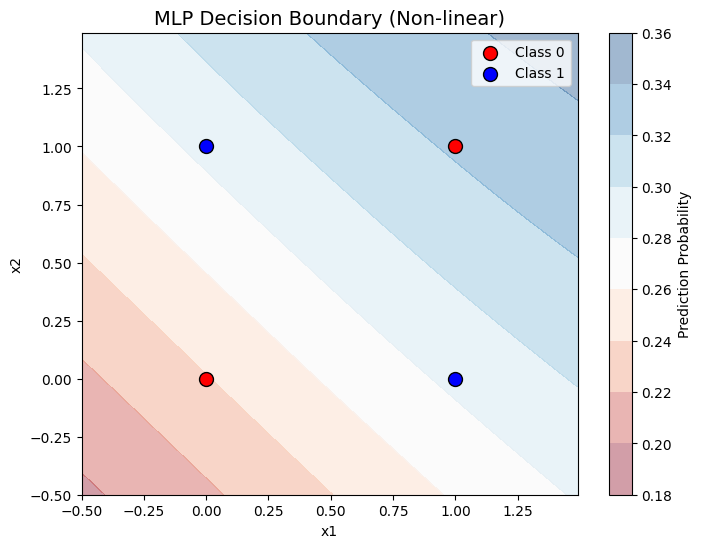

In [27]:
plot_decision_boundary(X, y, W1_2, b1_2, W2_2, b2_2)